# PROGRESS 1
**Judul proyek** : Analisis Perbandingan Metode SARIMA dan Holt-Winters dalam Peramalan Harga Komoditas Pangan di Jawa Timur

**Adinda Putri Rachmawati-2408301005**


**Import Library**

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings

from statsmodels.tsa.stattools import adfuller

warnings.filterwarnings('ignore')

plt.rcParams['figure.figsize'] = (12, 5)
sns.set_theme(style="whitegrid")

**Memuat Data**

In [4]:
file_harga = '/content/Harga_Pangan_Jawa_Timur_2025_12_Bulan_dengan_Estimasi.csv'
file_nbm = '/content/Neraca Bahan Makanan_ NBM 2025.xlsx'

# Memastikan file tersedia
print("File di folder Colab:")
print(os.listdir('/content/'))

if not os.path.exists(file_harga):
    raise FileNotFoundError(f"File tidak ditemukan: {file_harga}")

if not os.path.exists(file_nbm):
    raise FileNotFoundError(f"File tidak ditemukan: {file_nbm}")

# Membaca dataset harga pangan
harga = pd.read_csv(file_harga)

# Membaca seluruh sheet NBM
nbm_sheets = pd.read_excel(file_nbm, sheet_name=None)

print("\nDataset berhasil dibaca!")

File di folder Colab:
['.config', 'Harga_Pangan_Jawa_Timur_2025_12_Bulan_dengan_Estimasi.csv', 'Neraca Bahan Makanan_ NBM 2025.xlsx', 'sample_data']

Dataset berhasil dibaca!


In [6]:
# Menggunakan data yang sudah dibaca pada Progress 1

harga_aktual = harga.copy()

# Konversi kolom menjadi numerik
harga_aktual["Harga (Rp)"] = pd.to_numeric(
    harga_aktual["Harga (Rp)"],
    errors="coerce"
)

harga_aktual["Tahun"] = pd.to_numeric(
    harga_aktual["Tahun"],
    errors="coerce"
)

harga_aktual["Urutan Bulan"] = pd.to_numeric(
    harga_aktual["Urutan Bulan"],
    errors="coerce"
)

# Membuat kolom tanggal
harga_aktual["Tanggal"] = pd.to_datetime(
    dict(
        year=harga_aktual["Tahun"],
        month=harga_aktual["Urutan Bulan"],
        day=1
    ),
    errors="coerce"
)

# Mengambil data aktual saja
harga_aktual = harga_aktual[
    harga_aktual["Status Data"]
    .astype(str)
    .str.upper()
    .str.startswith("AKTUAL")
].copy()

# Menghapus data kosong
harga_aktual = harga_aktual.dropna(
    subset=["Tanggal", "Harga (Rp)", "Komoditas"]
)

harga_aktual = harga_aktual.sort_values("Tanggal")

print("Data aktual berhasil disiapkan.")
display(harga_aktual.head())

Data aktual berhasil disiapkan.


,Kode Provinsi,Nama Provinsi,Tahun,Urutan Bulan,Bulan,Komoditas,Harga,Harga (Rp),Status Data,Metode Estimasi,Sumber Acuan,Tanggal
0,35,Jawa Timur,2025,1,Januari,Bawang Merah,"Rp34,046",34046.0,AKTUAL - SESUAI FILE SUMBER,NaN,Dataset Bapanas yang diunggah pengguna (data a...,2025-01-01
72,35,Jawa Timur,2025,1,Januari,Cabai Merah Keriting,"Rp50,167",50167.0,AKTUAL - SESUAI FILE SUMBER,NaN,Dataset Bapanas yang diunggah pengguna (data a...,2025-01-01
36,35,Jawa Timur,2025,1,Januari,Beras Premium,"Rp14,560",14560.0,AKTUAL - SESUAI FILE SUMBER,NaN,Dataset Bapanas yang diunggah pengguna (data a...,2025-01-01
84,35,Jawa Timur,2025,1,Januari,Cabai Rawit Merah,"Rp71,199",71199.0,AKTUAL - SESUAI FILE SUMBER,NaN,Dataset Bapanas yang diunggah pengguna (data a...,2025-01-01
96,35,Jawa Timur,2025,1,Januari,Daging Ayam Ras,"Rp34,470",34470.0,AKTUAL - SESUAI FILE SUMBER,NaN,Dataset Bapanas yang diunggah pengguna (data a...,2025-01-01


In [7]:
daftar_komoditas = sorted(
    harga_aktual["Komoditas"]
    .dropna()
    .unique()
)

print("Jumlah komoditas:", len(daftar_komoditas))

for nomor, komoditas in enumerate(daftar_komoditas, start=1):
    print(f"{nomor}. {komoditas}")

Jumlah komoditas: 25
1. Bawang Merah
2. Bawang Putih (Bonggol)
3. Beras Medium
4. Beras Premium
5. Beras SPHP
6. Cabai Merah Besar
7. Cabai Merah Keriting
8. Cabai Rawit Merah
9. Daging Ayam Ras
10. Daging Kerbau Beku (Impor)
11. Daging Kerbau Segar (Lokal)
12. Daging Sapi Murni
13. Garam Konsumsi
14. Gula Pasir Lokal/Curah
15. Ikan Bandeng
16. Ikan Kembung
17. Ikan Tongkol
18. Jagung Tingkat Peternak
19. Kedelai Biji Kering
20. Minyak Goreng Curah
21. Minyak Goreng Kemasan
22. Minyak Kita
23. Telur Ayam Ras
24. Tepung Terigu Curah
25. Tepung Terigu Kemasan


In [8]:
# Menggunakan data harga aktual
data_time_series = harga_aktual.copy()

# Mengurutkan data berdasarkan komoditas dan tanggal
data_time_series = data_time_series.sort_values(
    by=["Komoditas", "Tanggal"]
)

# Mengelompokkan harga berdasarkan bulan dan komoditas
data_bulanan = (
    data_time_series
    .groupby(["Tanggal", "Komoditas"])["Harga (Rp)"]
    .mean()
    .reset_index()
)

print("Data time series berhasil disiapkan.")

display(data_bulanan.head(10))

Data time series berhasil disiapkan.


,Tanggal,Komoditas,Harga (Rp)
0,2025-01-01,Bawang Merah,34046.0
1,2025-01-01,Bawang Putih (Bonggol),38129.0
2,2025-01-01,Beras Medium,12705.0
3,2025-01-01,Beras Premium,14560.0
4,2025-01-01,Beras SPHP,11975.0
5,2025-01-01,Cabai Merah Keriting,50167.0
6,2025-01-01,Cabai Rawit Merah,71199.0
7,2025-01-01,Daging Ayam Ras,34470.0
8,2025-01-01,Daging Sapi Murni,117514.0
9,2025-01-01,Garam Konsumsi,9487.0


**Memilih komoditas yang akan di analisis**

In [16]:
# Memilih komoditas yang akan dianalisis

komoditas_pilihan = [
    'Beras Medium',
    'Cabai Rawit Merah',
    'Daging Ayam Ras',
    'Telur Ayam Ras',
    'Minyak Goreng Curah'
]

# Menampilkan data berdasarkan komoditas pilihan (menggunakan data_bulanan yang telah didefinisikan)
data_pilihan = data_bulanan[
    data_bulanan['Komoditas'].isin(komoditas_pilihan)
].copy()

print("Jumlah data setelah pemilihan komoditas:", len(data_pilihan))
print("\nKomoditas yang dipilih:")
print(data_pilihan['Komoditas'].unique())

Jumlah data setelah pemilihan komoditas: 55

Komoditas yang dipilih:
['Beras Medium' 'Cabai Rawit Merah' 'Daging Ayam Ras'
 'Minyak Goreng Curah' 'Telur Ayam Ras']


In [21]:
# Melihat jumlah data observasi untuk setiap komoditas pilihan

rekap_komoditas = data_pilihan.groupby(
    ['Komoditas']
).size().reset_index(name='Jumlah Data Bulanan')

display(rekap_komoditas)

,Komoditas,Jumlah Data Bulanan
0,Beras Medium,11
1,Cabai Rawit Merah,11
2,Daging Ayam Ras,11
3,Minyak Goreng Curah,11
4,Telur Ayam Ras,11


In [26]:
# Mengubah harga menjadi numerik
data_pilihan['Harga (Rp)'] = pd.to_numeric(
    data_pilihan['Harga (Rp)'],
    errors='coerce'
)

# Menghapus data harga atau tanggal yang kosong
harga_terpilih = data_pilihan.dropna(
    subset=['Tanggal', 'Harga (Rp)']
).copy()

# Mengurutkan data berdasarkan komoditas dan tanggal
harga_terpilih = harga_terpilih.sort_values(
    ['Komoditas', 'Tanggal']
)

display(harga_terpilih.head())

,Tanggal,Komoditas,Harga (Rp)
2,2025-01-01,Beras Medium,12705.0
23,2025-02-01,Beras Medium,12733.0
46,2025-03-01,Beras Medium,12812.0
69,2025-04-01,Beras Medium,12809.0
92,2025-05-01,Beras Medium,12742.0


In [27]:
data_time_series = harga_terpilih.groupby(
    ['Tanggal', 'Komoditas']
)['Harga (Rp)'].mean().reset_index()

display(data_time_series.head())

,Tanggal,Komoditas,Harga (Rp)
0,2025-01-01,Beras Medium,12705.0
1,2025-01-01,Cabai Rawit Merah,71199.0
2,2025-01-01,Daging Ayam Ras,34470.0
3,2025-01-01,Minyak Goreng Curah,18266.0
4,2025-01-01,Telur Ayam Ras,26642.0


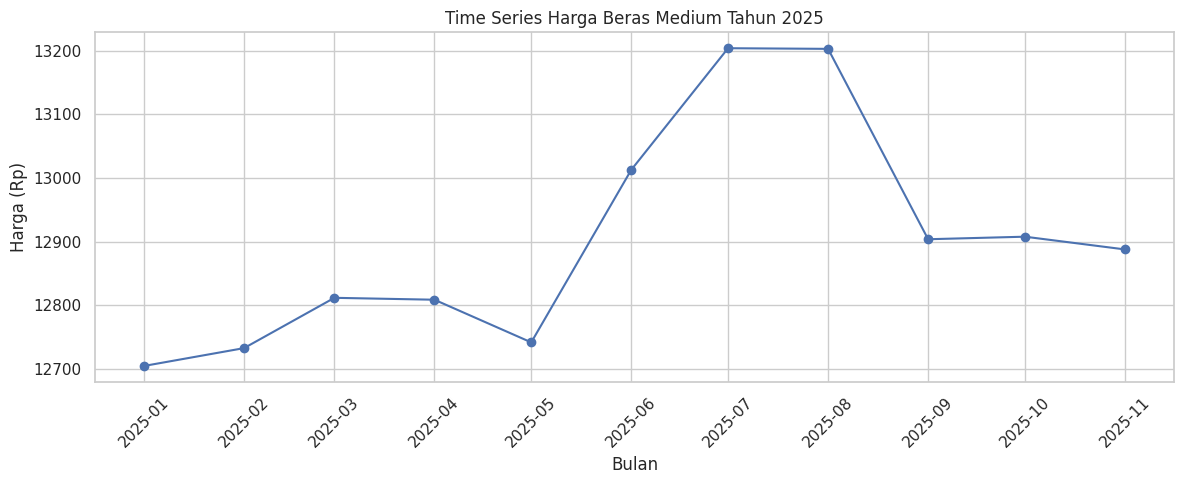

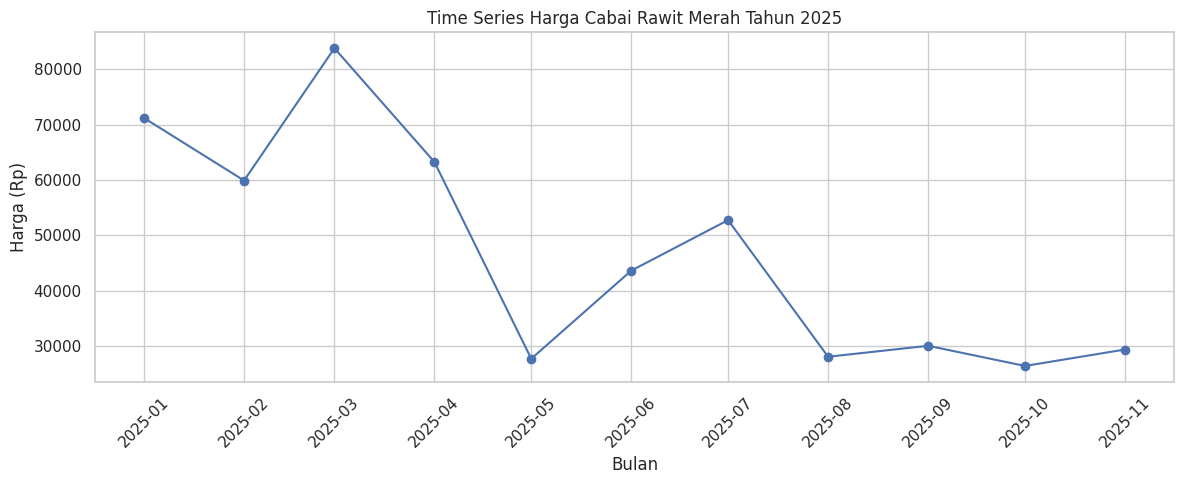

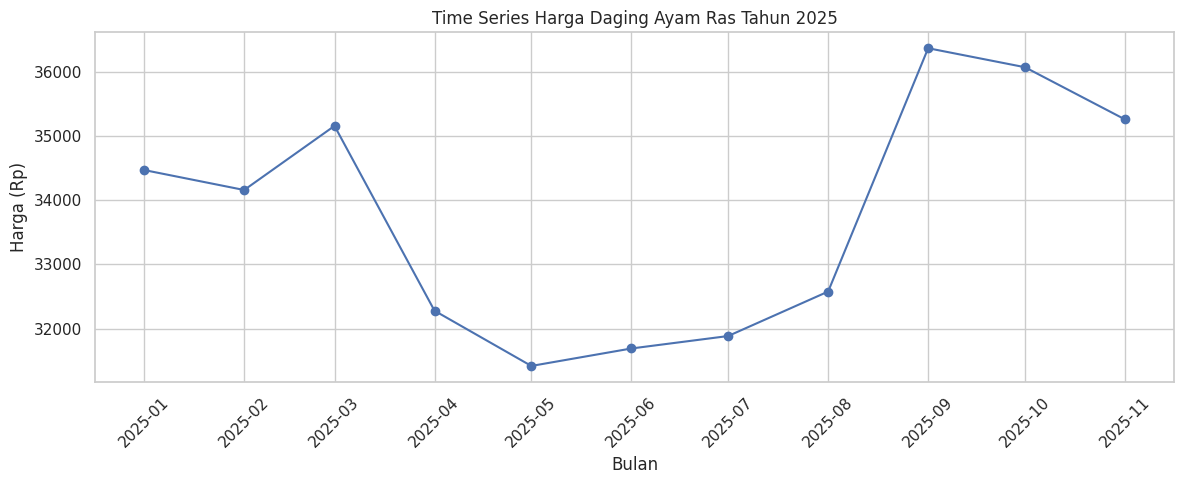

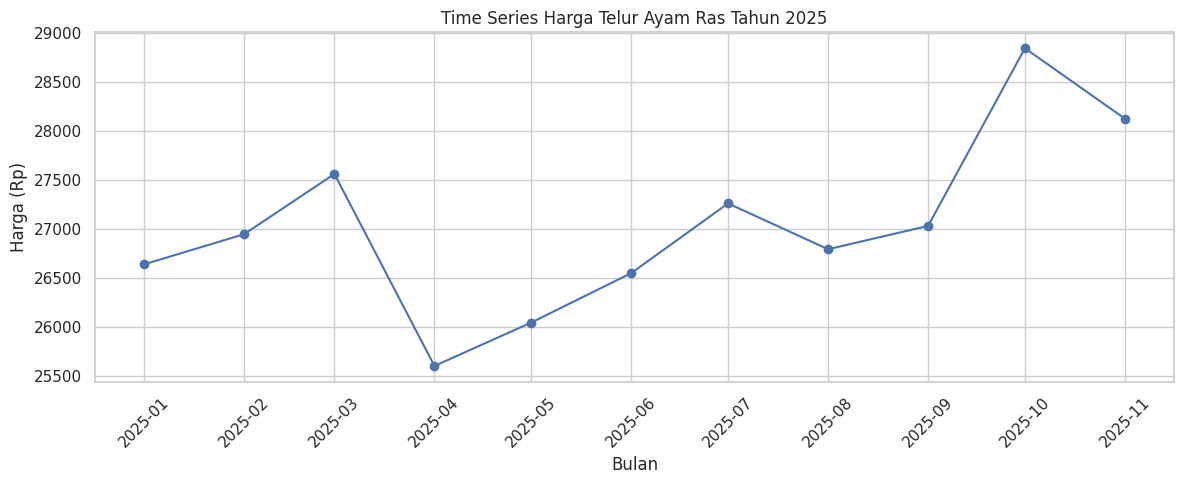

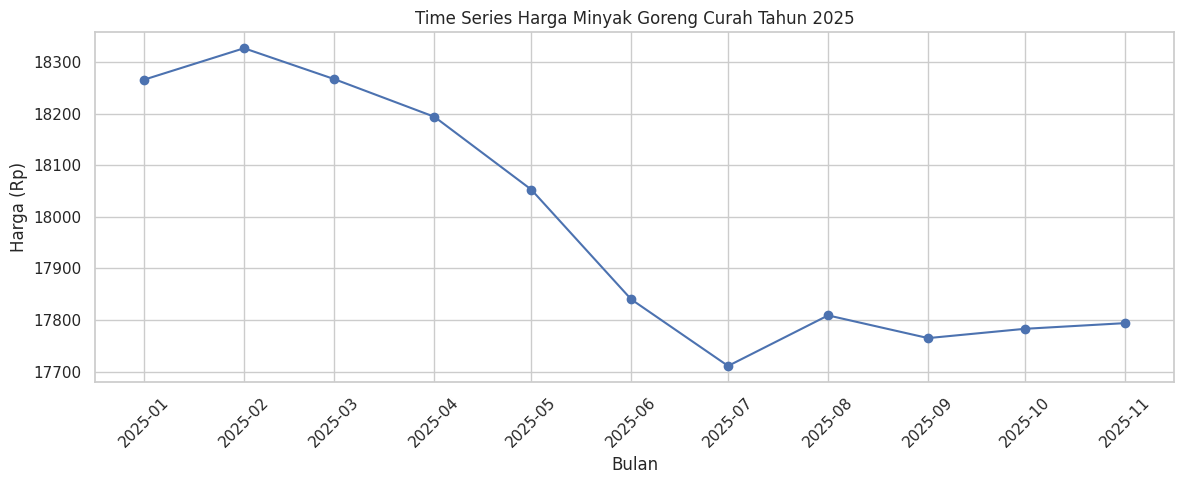

In [28]:
import matplotlib.pyplot as plt

for komoditas in komoditas_pilihan:

    data_komoditas = data_time_series[
        data_time_series['Komoditas'] == komoditas
    ]

    plt.figure(figsize=(12, 5))

    plt.plot(
        data_komoditas['Tanggal'],
        data_komoditas['Harga (Rp)'],
        marker='o'
    )

    plt.title(f'Time Series Harga {komoditas} Tahun 2025')
    plt.xlabel('Bulan')
    plt.ylabel('Harga (Rp)')
    plt.xticks(rotation=45)
    plt.grid(True)
    plt.tight_layout()
    plt.show()

**UJi Stasioneritas**

In [29]:
hasil_adf = []

for komoditas in komoditas_pilihan:

    data_komoditas = data_time_series[
        data_time_series['Komoditas'] == komoditas
    ].sort_values('Tanggal')

    harga = data_komoditas['Harga (Rp)'].dropna()

    adf_test = adfuller(harga, autolag='AIC')

    hasil_adf.append({
        'Komoditas': komoditas,
        'ADF Statistic': adf_test[0],
        'P-Value': adf_test[1],
        'Critical Value 5%': adf_test[4]['5%'],
        'Kesimpulan': 'Stasioner' if adf_test[1] < 0.05 else 'Non-Stasioner'
    })

tabel_adf = pd.DataFrame(hasil_adf)

display(tabel_adf)

,Komoditas,ADF Statistic,P-Value,Critical Value 5%,Kesimpulan
0,Beras Medium,-1.979595,0.295591,-3.289881,Non-Stasioner
1,Cabai Rawit Merah,-2.573129,0.098679,-3.477583,Non-Stasioner
2,Daging Ayam Ras,-2.091356,0.248005,-3.477583,Non-Stasioner
3,Telur Ayam Ras,-1.637112,0.463770,-3.232950,Non-Stasioner
4,Minyak Goreng Curah,-0.934009,0.776567,-3.232950,Non-Stasioner
